In [1]:
# Libraries for data analysis and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries loaded successfully!")

Libraries loaded successfully!


# Crypto Market Health Monitor
### Cross-Asset Monitoring of BTC, ETH and SOL Using Kraken Market Data

## Project Overview

Crypto markets operate continuously and can experience sudden changes in price, trading activity and volatility across multiple assets at the same time. Monitoring these signals manually can make it difficult to identify the periods that deserve closer investigation.

This project develops a rule-based market monitoring prototype using hourly Kraken data for BTC/USD, ETH/USD and SOL/USD.

The objective is to transform raw market data into a simple monitoring workflow that:

- measures hourly price movements and rolling volatility;
- identifies unusually high trading activity;
- classifies each asset as NORMAL, WATCH or ALERT;
- detects periods when several assets enter ALERT simultaneously;
- groups simultaneous alerts into distinct market episodes; and
- provides a structured starting point for further market research.

The project is designed as a market-monitoring and research prototype rather than a trading or price-prediction model.

## Analysis Pipeline

Kraken OHLC Data  
→ Data Cleaning  
→ Feature Engineering  
→ Asset-Level Market Health Classification  
→ Cross-Asset Alert Detection  
→ Episode Grouping  
→ Market Behaviour Analysis  
→ Research and Product Insights

## 2. Data Source & Scope

Market data was collected from the Kraken public OHLC API for three USD trading pairs:

- **BTC/USD**
- **ETH/USD**
- **SOL/USD**

The dataset contains **721 hourly observations per asset**, covering approximately 30 days from **31 August 2026 to 30 September 2026**.

Each observation contains:

- Open, high, low and close (OHLC) prices
- Volume-weighted average price (VWAP)
- Trading volume
- Number of trades

### Scope

The analysis focuses on short-term market behaviour across the three selected crypto assets. The same analytical framework is applied independently to each asset before their signals are combined for cross-asset monitoring.

The dataset represents activity from the selected **Kraken USD trading pairs only** and should not be interpreted as representing total global cryptocurrency market activity.

## 3. Data Collection

### Load the Frozen Dataset

The analysis uses fixed CSV snapshots to ensure that the same market period can be reproduced.

Place `btc_kraken_market_data.csv`, `eth_kraken_market_data.csv`, and
`sol_kraken_market_data.csv` in the same folder when running locally.
In Google Colab, the loading cell will prompt for the files if they are not already uploaded.
The main analysis uses these saved snapshots rather than fetching changing live data.

In [2]:
# Locate the three frozen CSV snapshots (Google Colab or a local project folder).
from pathlib import Path

required_files = [
    "btc_kraken_market_data.csv",
    "eth_kraken_market_data.csv",
    "sol_kraken_market_data.csv",
]
search_dirs = [Path.cwd(), Path("/content"), Path("/mnt/data")]

def find_data_dir():
    for directory in search_dirs:
        if all((directory / filename).is_file() for filename in required_files):
            return directory
    return None

data_dir = find_data_dir()
if data_dir is None:
    try:
        from google.colab import files
    except ImportError as exc:
        raise FileNotFoundError(
            "Place the three Kraken CSV files in the same folder as the notebook "
            "and run it from that folder."
        ) from exc
    print("Please upload the three Kraken CSV files.")
    files.upload()
    data_dir = find_data_dir()

if data_dir is None:
    raise FileNotFoundError(
        "Could not find all three CSV files: " + ", ".join(required_files)
    )

print(f"Loading frozen market data from: {data_dir}")

Loading frozen market data from: /content


In [3]:
# Load fixed Kraken market-data snapshots
btc = pd.read_csv(data_dir / required_files[0])
eth = pd.read_csv(data_dir / required_files[1])
sol = pd.read_csv(data_dir / required_files[2])

# Convert datetime strings to timestamps; keep the input snapshots unchanged.
for df in (btc, eth, sol):
    df["datetime"] = pd.to_datetime(df["datetime"])
    df.sort_values("datetime", inplace=True)
    df.reset_index(drop=True, inplace=True)

print("BTC:", btc["datetime"].min(), "→", btc["datetime"].max(), btc.shape)
print("ETH:", eth["datetime"].min(), "→", eth["datetime"].max(), eth.shape)
print("SOL:", sol["datetime"].min(), "→", sol["datetime"].max(), sol.shape)

BTC: 2026-08-31 16:00:00 → 2026-09-30 16:00:00 (721, 13)
ETH: 2026-08-31 16:00:00 → 2026-09-30 16:00:00 (721, 13)
SOL: 2026-08-31 16:00:00 → 2026-09-30 16:00:00 (721, 13)


The original market data was collected from Kraken's public OHLC API and saved as fixed CSV snapshots to preserve a consistent analysis period.

Using fixed snapshots ensures that the results in this notebook remain reproducible, since the Kraken OHLC endpoint returns recent rolling market data and may produce a different time window when queried at a later date.

The three datasets used in the analysis are:

- `btc_kraken_market_data.csv`
- `eth_kraken_market_data.csv`
- `sol_kraken_market_data.csv`

For this portfolio analysis, the saved datasets are loaded directly rather than requesting live market data each time the notebook is executed.

## 4. Data Preparation & Feature Engineering

To support market monitoring, additional indicators were derived from the hourly Kraken data. These features capture the magnitude of price movements, recent volatility and unusual trading activity for each asset.

The main engineered features are:

- **Hourly Price Change (%)** – percentage change in closing price from the previous hour.
- **Absolute Price Change** – magnitude of the hourly price movement regardless of direction.
- **24-Hour Rolling Volatility** – rolling standard deviation of hourly price changes over the previous 24 observations.
- **Alert Score** – number of market indicators exceeding their asset-specific thresholds.
- **Market Status** – classification of each observation as NORMAL, WATCH or ALERT.

In [4]:
def add_market_health(df):
    df = df.copy()

    # Calculate market indicators
    df["price_change_pct"] = df["close"].pct_change() * 100
    df["abs_price_change"] = df["price_change_pct"].abs()
    df["volatility_24h"] = df["price_change_pct"].rolling(window=24).std()

    # Asset-specific 90th percentile thresholds
    price_threshold = df["abs_price_change"].quantile(0.90)
    volume_threshold = df["volume"].quantile(0.90)
    volatility_threshold = df["volatility_24h"].quantile(0.90)

    # Count how many indicators exceed their thresholds
    df["alert_score"] = (
        (df["abs_price_change"] > price_threshold).astype(int)
        + (df["volume"] > volume_threshold).astype(int)
        + (df["volatility_24h"] > volatility_threshold).astype(int)
    )

    # Convert the score into a market-health status
    def market_status(score):
        if score >= 2:
            return "ALERT"
        elif score == 1:
            return "WATCH"
        else:
            return "NORMAL"

    df["market_status"] = df["alert_score"].apply(market_status)

    return df

In [5]:
# Keep only the original Kraken market fields
raw_columns = [
    "datetime", "open", "high", "low",
    "close", "vwap", "volume", "trade_count"
]

btc_raw = btc[raw_columns].copy()
eth_raw = eth[raw_columns].copy()
sol_raw = sol[raw_columns].copy()

# Rebuild the market-health features consistently for each asset
btc = add_market_health(btc_raw)
eth = add_market_health(eth_raw)
sol = add_market_health(sol_raw)

print("BTC:", btc.shape)
print("ETH:", eth.shape)
print("SOL:", sol.shape)

BTC: (721, 13)
ETH: (721, 13)
SOL: (721, 13)


In [6]:
# Calculate data-based thresholds for the Market Health Monitor

thresholds = btc[
    ["abs_price_change", "volume", "volatility_24h"]
].quantile([0.50, 0.75, 0.90, 0.95])

thresholds.round(2)

,abs_price_change,volume,volatility_24h
0.50,0.16,72.30,0.32
0.75,0.32,128.94,0.42
0.90,0.53,230.95,0.57
0.95,0.75,318.40,0.59


In [7]:
# Calculate the 90th percentile thresholds used for each asset
thresholds = []

for name, df in [("BTC", btc), ("ETH", eth), ("SOL", sol)]:
    thresholds.append({
        "Asset": name,
        "Price Movement (%)": df["abs_price_change"].quantile(0.90),
        "Volume": df["volume"].quantile(0.90),
        "24h Volatility (%)": df["volatility_24h"].quantile(0.90)
    })

threshold_table = pd.DataFrame(thresholds).round(2)
threshold_table

,Asset,Price Movement (%),Volume,24h Volatility (%)
0,BTC,0.53,230.95,0.57
1,ETH,0.69,3007.27,0.65
2,SOL,0.89,39088.50,0.79


### Threshold Interpretation

The thresholds differ across assets because each asset is evaluated relative to its own observed behaviour.

For example, an absolute hourly price movement above approximately **0.53% for BTC**, **0.69% for ETH**, or **0.89% for SOL** falls within the most extreme 10% of price movements observed for that asset during the sample period.

The same principle is applied independently to trading volume and 24-hour rolling volatility. These thresholds are therefore used as monitoring signals rather than as universal measures of market risk.

## 5. Asset-Level Market Health Analysis

The market-health framework classifies each hourly observation according to the number of unusual indicators detected.

- **NORMAL:** none of the three indicators exceeds its asset-specific 90th percentile threshold.
- **WATCH:** one indicator exceeds its threshold.
- **ALERT:** two or more indicators exceed their thresholds.

Using asset-specific thresholds allows BTC, ETH and SOL to be evaluated relative to their own observed market behaviour rather than comparing their raw price movements, volume or volatility directly.

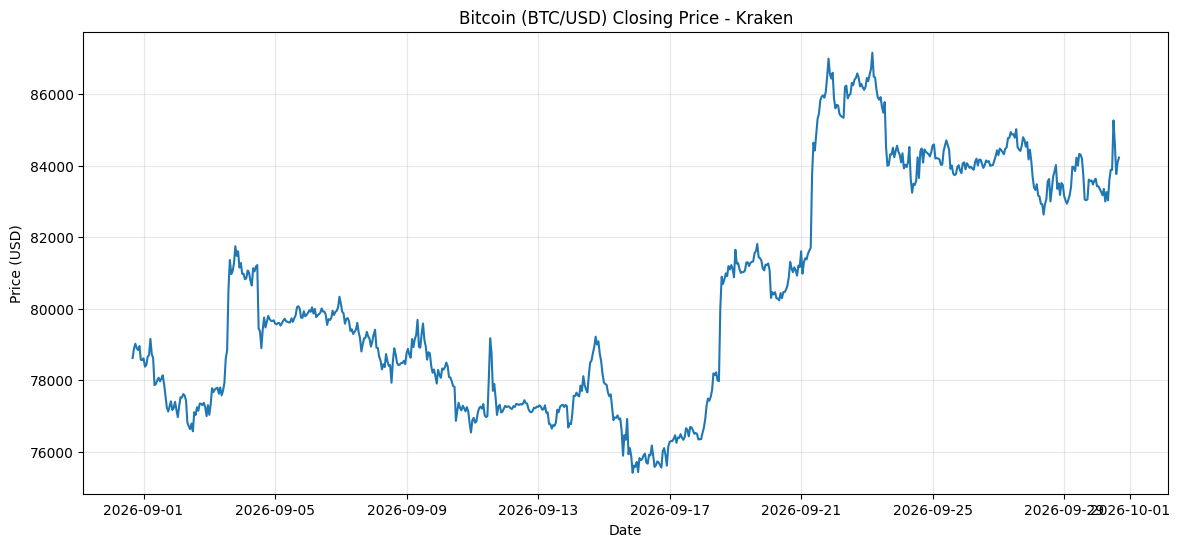

In [8]:
# Plot Bitcoin's hourly closing price to understand how its price changed over time

plt.figure(figsize=(14, 6))

plt.plot(btc["datetime"], btc["close"])

plt.title("Bitcoin (BTC/USD) Closing Price - Kraken")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.grid(alpha=0.3)

plt.show()

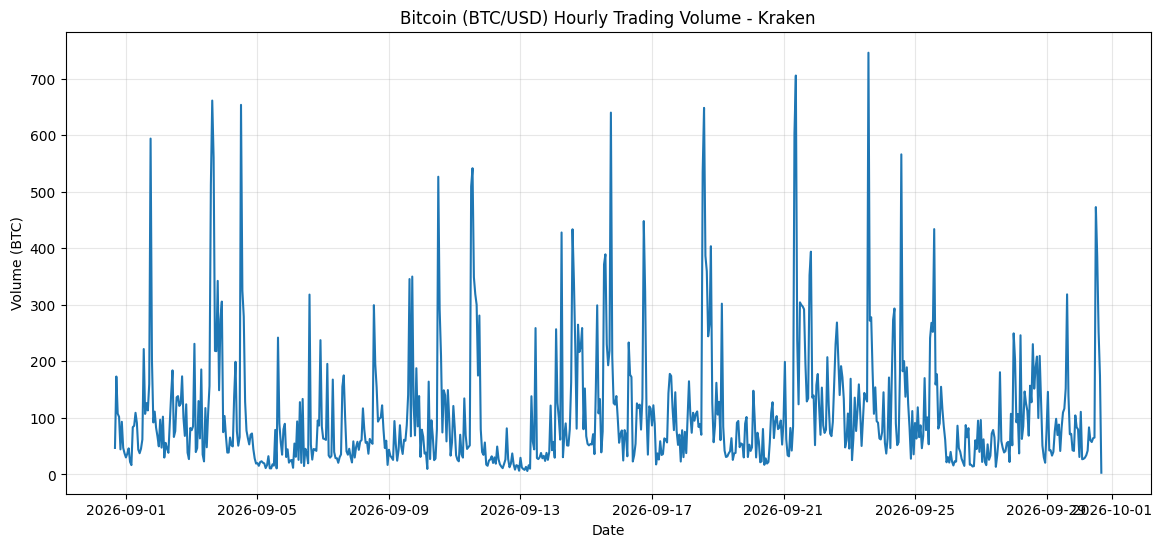

In [9]:
# Plot hourly Bitcoin trading volume to see when market activity increased or decreased

plt.figure(figsize=(14, 6))

plt.plot(btc["datetime"], btc["volume"])

plt.title("Bitcoin (BTC/USD) Hourly Trading Volume - Kraken")
plt.xlabel("Date")
plt.ylabel("Volume (BTC)")
plt.grid(alpha=0.3)

plt.show()

In [10]:
# Summarize the main market-health indicators to understand their typical and extreme values

health_summary = btc[
    ["price_change_pct", "volume", "volatility_24h"]
].describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95])

health_summary.round(2)

,price_change_pct,volume,volatility_24h
count,720.00,721.00,697.00
mean,0.01,106.71,0.34
std,0.37,109.60,0.14
min,-2.19,3.03,0.07
25%,-0.15,38.26,0.25
50%,0.00,72.30,0.32
75%,0.17,128.94,0.42
90%,0.36,230.95,0.57
95%,0.53,318.40,0.59
max,2.60,745.68,0.74


In [11]:
# Compare how often BTC, ETH and SOL were classified
# as NORMAL, WATCH or ALERT

def status_distribution(df, asset):

    counts = df["market_status"].value_counts()
    percentages = df["market_status"].value_counts(normalize=True) * 100

    return pd.DataFrame({
        "asset": asset,
        "status": counts.index,
        "count": counts.values,
        "percentage": percentages.values
    })


btc_status = status_distribution(btc, "BTC")
eth_status = status_distribution(eth, "ETH")
sol_status = status_distribution(sol, "SOL")

status_comparison = pd.concat(
    [btc_status, eth_status, sol_status],
    ignore_index=True
)

status_comparison["percentage"] = status_comparison["percentage"].round(2)

status_comparison

,asset,status,count,percentage
0,BTC,NORMAL,561,77.81
1,BTC,WATCH,113,15.67
2,BTC,ALERT,47,6.52
3,ETH,NORMAL,553,76.70
4,ETH,WATCH,131,18.17
5,ETH,ALERT,37,5.13
6,SOL,NORMAL,559,77.53
7,SOL,WATCH,121,16.78
8,SOL,ALERT,41,5.69


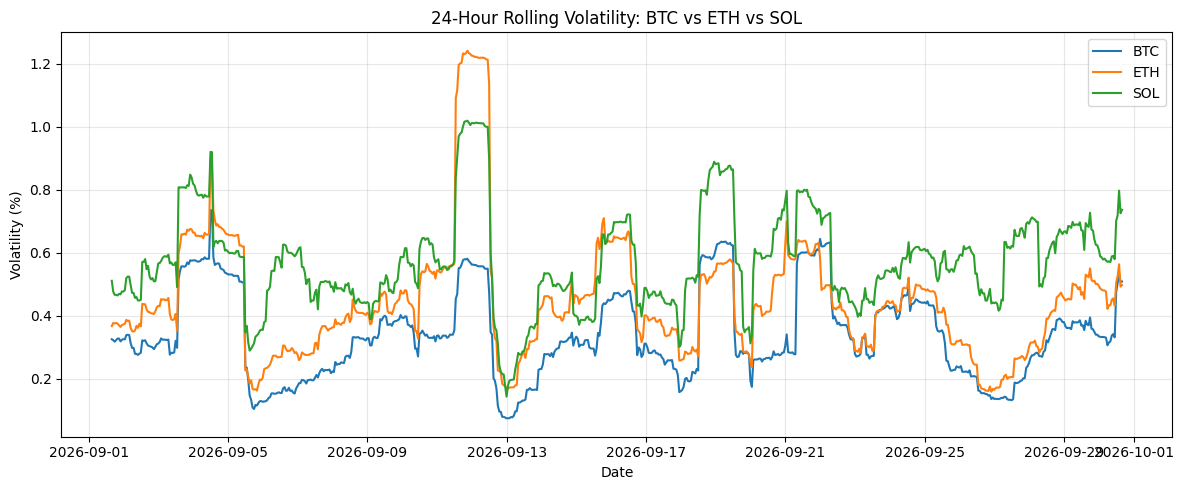

In [12]:
plt.figure(figsize=(12, 5))

plt.plot(btc["datetime"], btc["volatility_24h"], label="BTC")
plt.plot(eth["datetime"], eth["volatility_24h"], label="ETH")
plt.plot(sol["datetime"], sol["volatility_24h"], label="SOL")

plt.title("24-Hour Rolling Volatility: BTC vs ETH vs SOL")
plt.xlabel("Date")
plt.ylabel("Volatility (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

### Volatility Comparison

The three assets show distinct volatility patterns during the sample period.

- **SOL recorded the highest typical volatility**, with an average 24-hour rolling volatility of approximately **0.57%**.
- **ETH experienced the largest volatility peak**, reaching approximately **1.24%**.
- **BTC was comparatively less volatile**, with an average rolling volatility of approximately **0.34%**.

Several volatility increases also occur across multiple assets around similar periods, suggesting that some episodes of unusual market activity were not isolated to a single asset.

Because volatility is calculated using a rolling 24-hour window, elevated values can persist after a large market movement. The chart therefore reflects recent market variability rather than only the movement occurring in an individual hour.

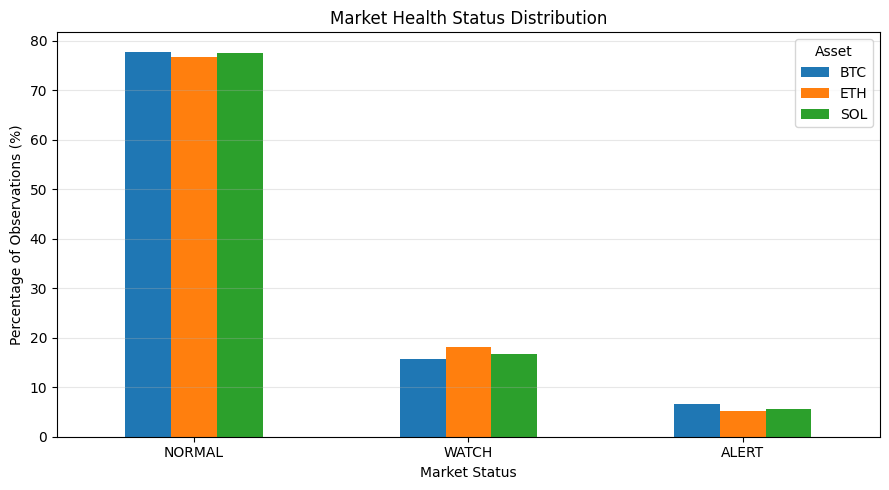

In [13]:
# Calculate percentage distribution of market-health statuses
status_order = ["NORMAL", "WATCH", "ALERT"]

status_percentages = pd.DataFrame({
    "BTC": btc["market_status"].value_counts(normalize=True).reindex(status_order) * 100,
    "ETH": eth["market_status"].value_counts(normalize=True).reindex(status_order) * 100,
    "SOL": sol["market_status"].value_counts(normalize=True).reindex(status_order) * 100
})

# Plot status distribution
ax = status_percentages.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Market Health Status Distribution")
plt.xlabel("Market Status")
plt.ylabel("Percentage of Observations (%)")
plt.xticks(rotation=0)
plt.legend(title="Asset")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()

In [14]:
# Compare the actual 24-hour volatility of BTC, ETH and SOL

volatility_comparison = pd.DataFrame({
    "Asset": ["BTC", "ETH", "SOL"],
    "Average Volatility": [
        btc["volatility_24h"].mean(),
        eth["volatility_24h"].mean(),
        sol["volatility_24h"].mean()
    ],
    "Median Volatility": [
        btc["volatility_24h"].median(),
        eth["volatility_24h"].median(),
        sol["volatility_24h"].median()
    ],
    "Maximum Volatility": [
        btc["volatility_24h"].max(),
        eth["volatility_24h"].max(),
        sol["volatility_24h"].max()
    ]
})

volatility_comparison.round(2)

,Asset,Average Volatility,Median Volatility,Maximum Volatility
0,BTC,0.34,0.32,0.74
1,ETH,0.45,0.42,1.24
2,SOL,0.57,0.56,1.02


### Market Health Distribution

Most hourly observations were classified as **NORMAL** across all three assets, accounting for approximately **77%** of the sample.

**WATCH** observations represented approximately **16–18%**, while only **5–7%** of observations were classified as **ALERT**.

This distribution shows that the rule-based framework filters the hourly market data into a smaller set of unusual observations for further investigation. Importantly, an ALERT does not indicate that the market is necessarily falling or that a trading opportunity exists. It indicates that at least two of the monitored signals — price movement, trading volume and rolling volatility — were unusually high relative to that asset's observed behaviour.

## 6. Cross-Asset Alert Detection

Asset-level alerts identify unusual behaviour within BTC, ETH or SOL individually. However, simultaneous alerts across multiple assets may provide a stronger signal of broader market activity.

To examine this, the hourly market status of BTC, ETH and SOL was aligned by timestamp. For each hour, the number of assets classified as ALERT was counted.

This produces four possible cross-asset states:

- **0 assets in ALERT** – no selected asset triggered an alert.
- **1 asset in ALERT** – unusual activity was isolated to one asset.
- **2 assets in ALERT** – unusual activity occurred simultaneously in two assets.
- **3 assets in ALERT** – BTC, ETH and SOL were all simultaneously classified as ALERT.

The final category is used to identify periods for deeper market investigation.

In [15]:
# Align the market status of all three assets by timestamp
combined_status = (
    btc[["datetime", "market_status"]]
    .rename(columns={"market_status": "BTC_status"})
    .merge(
        eth[["datetime", "market_status"]]
        .rename(columns={"market_status": "ETH_status"}),
        on="datetime"
    )
    .merge(
        sol[["datetime", "market_status"]]
        .rename(columns={"market_status": "SOL_status"}),
        on="datetime"
    )
)

# Count how many assets are simultaneously in ALERT
combined_status["number_of_alerts"] = (
    (combined_status["BTC_status"] == "ALERT").astype(int)
    + (combined_status["ETH_status"] == "ALERT").astype(int)
    + (combined_status["SOL_status"] == "ALERT").astype(int)
)

# Display the distribution
combined_status["number_of_alerts"].value_counts().sort_index()

,count
number_of_alerts,
0,649
1,37
2,17
3,18


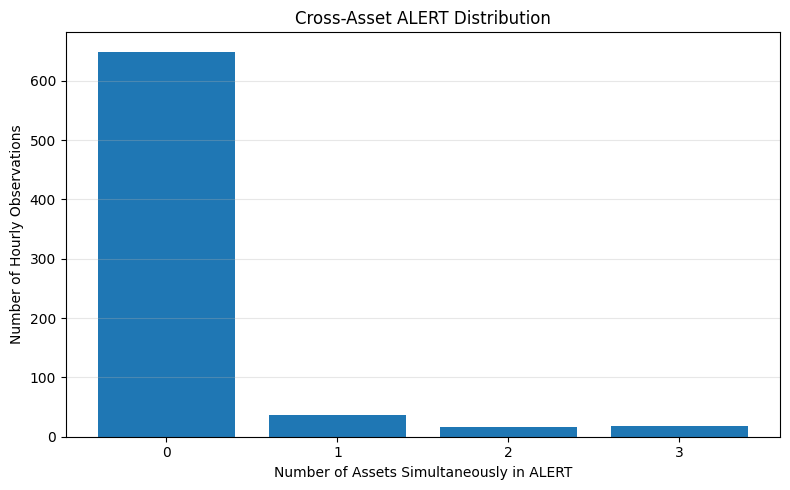

In [16]:
# Count hours by number of assets simultaneously in ALERT
alert_distribution = (
    combined_status["number_of_alerts"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(8, 5))

plt.bar(
    alert_distribution.index,
    alert_distribution.values
)

plt.title("Cross-Asset ALERT Distribution")
plt.xlabel("Number of Assets Simultaneously in ALERT")
plt.ylabel("Number of Hourly Observations")
plt.xticks([0, 1, 2, 3])
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()

### Cross-Asset Alert Distribution

Across the **721 hourly observations**, no selected asset was in ALERT during **649 hours (90.0%)**.

Simultaneous alerts became progressively less common:

- **37 hours** contained an ALERT in one asset.
- **17 hours** contained simultaneous ALERTs in two assets.
- **18 hours (2.5%)** contained simultaneous ALERTs across BTC, ETH and SOL.

The 18 triple-ALERT observations provide a focused subset of the dataset for deeper investigation. Rather than manually examining every hourly observation, the monitoring framework surfaces periods when unusual price movement, trading activity and volatility were occurring across multiple assets at the same time.

These simultaneous alerts are treated as investigation signals, not evidence by themselves of a specific market event or cause.

In [17]:
# Extract hours when BTC, ETH and SOL were all simultaneously in ALERT
triple_alerts = combined_status[
    combined_status["number_of_alerts"] == 3
].copy()

print("Total triple-ALERT hours:", len(triple_alerts))

triple_alerts[["datetime"]]

Total triple-ALERT hours: 18


,datetime
70,2026-09-03 14:00:00
71,2026-09-03 15:00:00
92,2026-09-04 12:00:00
236,2026-09-10 12:00:00
260,2026-09-11 12:00:00
261,2026-09-11 13:00:00
263,2026-09-11 15:00:00
266,2026-09-11 18:00:00
358,2026-09-15 14:00:00
362,2026-09-15 18:00:00


In [18]:
# Group nearby triple-ALERT observations into episodes
episodes = triple_alerts.copy()

episodes["hours_since_previous"] = (
    episodes["datetime"]
    .diff()
    .dt.total_seconds()
    .div(3600)
)

episodes["new_episode"] = (
    episodes["hours_since_previous"].isna()
    | (episodes["hours_since_previous"] > 3)
)

episodes["episode_id"] = episodes["new_episode"].cumsum()

# Summarise each episode
episode_summary = (
    episodes.groupby("episode_id")
    .agg(
        start_time=("datetime", "min"),
        end_time=("datetime", "max"),
        triple_alert_hours=("datetime", "count")
    )
    .reset_index()
)

episode_summary["episode_span_hours"] = (
    (episode_summary["end_time"] - episode_summary["start_time"])
    .dt.total_seconds()
    .div(3600) + 1
)

episode_summary

,episode_id,start_time,end_time,triple_alert_hours,episode_span_hours
0,1,2026-09-03 14:00:00,2026-09-03 15:00:00,2,2.0
1,2,2026-09-04 12:00:00,2026-09-04 12:00:00,1,1.0
2,3,2026-09-10 12:00:00,2026-09-10 12:00:00,1,1.0
3,4,2026-09-11 12:00:00,2026-09-11 18:00:00,4,7.0
4,5,2026-09-15 14:00:00,2026-09-15 14:00:00,1,1.0
5,6,2026-09-15 18:00:00,2026-09-15 18:00:00,1,1.0
6,7,2026-09-18 13:00:00,2026-09-18 14:00:00,2,2.0
7,8,2026-09-18 19:00:00,2026-09-18 19:00:00,1,1.0
8,9,2026-09-21 08:00:00,2026-09-21 09:00:00,2,2.0
9,10,2026-09-23 14:00:00,2026-09-23 14:00:00,1,1.0


### Episode Grouping

The 18 triple-ALERT observations were grouped into **11 distinct episodes** to avoid treating closely spaced alerts as completely separate events.

A new episode begins when the gap between consecutive triple-ALERT observations exceeds **3 hours**. The three-hour interval is a transparent analytical choice for this prototype rather than an industry-standard threshold.

Two measures are retained:

- **Triple-ALERT Hours:** the number of actual hourly observations in which BTC, ETH and SOL were simultaneously in ALERT.
- **Episode Span:** the elapsed period from the first to the last triple-ALERT observation within an episode.

These measures should not be interpreted as equivalent. For example, **Episode 4 spans seven hours but contains four triple-ALERT observations**, meaning the alert condition was not continuously active throughout the entire seven-hour period.

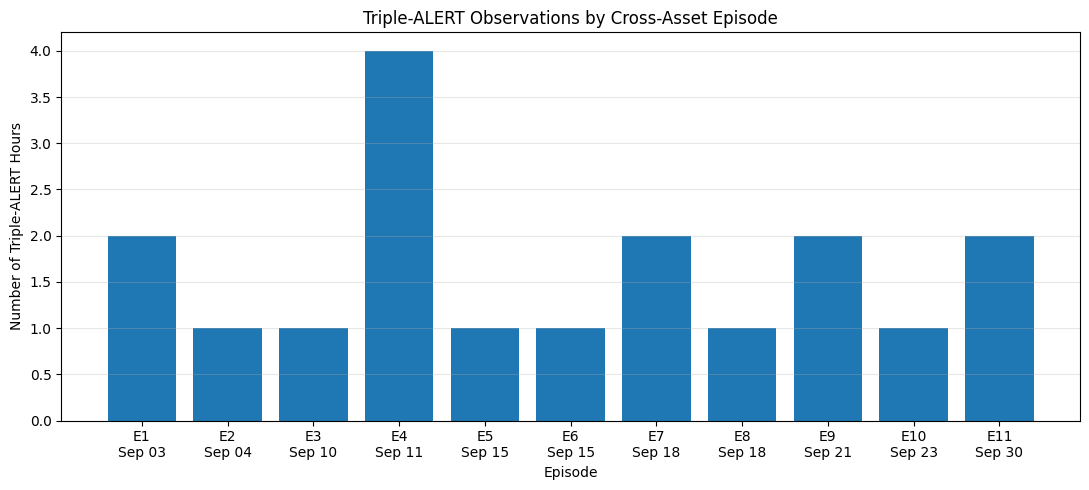

In [19]:
# Create readable labels for each episode
episode_summary["episode_label"] = (
    "E" + episode_summary["episode_id"].astype(str)
    + "\n"
    + episode_summary["start_time"].dt.strftime("%b %d")
)

plt.figure(figsize=(11, 5))

plt.bar(
    episode_summary["episode_label"],
    episode_summary["triple_alert_hours"]
)

plt.title("Triple-ALERT Observations by Cross-Asset Episode")
plt.xlabel("Episode")
plt.ylabel("Number of Triple-ALERT Hours")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()

### Cross-Asset Episode Pattern

The 18 triple-ALERT observations were concentrated within **11 distinct episodes**, showing that synchronized unusual activity occurred in clusters rather than being evenly distributed throughout the sample.

**Episode 4 (11 September)** contained the largest concentration, with **four triple-ALERT observations** between 12:00 and 18:00. Episodes 1, 7, 9 and 11 each contained two observations, while the remaining episodes contained one.

The number of observations within an episode indicates how frequently the cross-asset alert condition was detected during that period. It does not, by itself, measure the severity of the underlying market movement.

## 7. Market Behaviour During Cross-Asset ALERT Episodes

Detecting simultaneous alerts identifies when unusual activity occurred, but it does not explain how the market was behaving during those periods.

To investigate the 11 cross-asset episodes further, the analysis examines:

- the direction and magnitude of hourly price movements;
- differences in behaviour across BTC, ETH and SOL;
- rolling volatility during the alert periods; and
- trading activity relative to each asset's typical hourly level.

This helps distinguish different types of alert episodes, including upward movements, downward movements and periods where price direction changed within the same episode.

In [20]:
# Attach episode IDs to the hourly price movements
episode_market = (
    episodes[["datetime", "episode_id"]]
    .merge(
        btc[["datetime", "price_change_pct"]]
        .rename(columns={"price_change_pct": "BTC_change"}),
        on="datetime"
    )
    .merge(
        eth[["datetime", "price_change_pct"]]
        .rename(columns={"price_change_pct": "ETH_change"}),
        on="datetime"
    )
    .merge(
        sol[["datetime", "price_change_pct"]]
        .rename(columns={"price_change_pct": "SOL_change"}),
        on="datetime"
    )
)

# Summarise price behaviour within each episode
episode_price_summary = (
    episode_market.groupby("episode_id")
    .agg(
        BTC_avg_change=("BTC_change", "mean"),
        ETH_avg_change=("ETH_change", "mean"),
        SOL_avg_change=("SOL_change", "mean"),
        BTC_max_abs_change=("BTC_change", lambda x: x.abs().max()),
        ETH_max_abs_change=("ETH_change", lambda x: x.abs().max()),
        SOL_max_abs_change=("SOL_change", lambda x: x.abs().max())
    )
    .round(2)
    .reset_index()
)

episode_price_summary

,episode_id,BTC_avg_change,ETH_avg_change,SOL_avg_change,BTC_max_abs_change,ETH_max_abs_change,SOL_max_abs_change
0,1,1.59,1.78,1.79,2.17,2.46,3.28
1,2,-2.19,-2.83,-2.41,2.19,2.83,2.41
2,3,-1.22,-1.95,-2.06,1.22,1.95,2.06
3,4,0.21,0.97,0.71,1.48,4.76,3.17
4,5,-0.89,-1.88,-1.72,0.89,1.88,1.72
5,6,-1.28,-1.56,-2.02,1.28,1.56,2.02
6,7,1.86,1.60,2.33,2.60,2.11,2.62
7,8,0.35,0.94,1.85,0.35,0.94,1.85
8,9,1.78,1.10,1.69,2.50,1.31,2.84
9,10,-1.47,-1.46,-1.40,1.47,1.46,1.40


### Price Behaviour Across Episodes

The cross-asset ALERT episodes were not limited to market declines. Some episodes were associated with strong positive hourly movements, while others occurred during negative movements.

For example:

- **Episode 1** showed positive average movements across BTC, ETH and SOL.
- **Episodes 2, 3, 5, 6 and 10** showed negative average movements across all three assets.
- **Episode 7** showed particularly strong positive movements, with average changes of approximately 1.86% for BTC, 1.60% for ETH and 2.33% for SOL.
- **Episode 4** contained larger individual movements than its averages suggest, including a maximum absolute ETH movement of approximately 4.76%.
- **Episode 11** had average changes close to zero despite larger individual hourly movements, illustrating how movements in opposite directions can offset one another when averaged.

These results reinforce that the ALERT classification captures unusual market activity rather than a specific price direction. Episode averages should therefore be interpreted alongside the underlying hourly movements.

In [21]:
# Estimate hourly USD trading activity
for df in [btc, eth, sol]:
    df["volume_usd"] = df["vwap"] * df["volume"]

# Median hourly USD activity for each asset
btc_typical_volume = btc["volume_usd"].median()
eth_typical_volume = eth["volume_usd"].median()
sol_typical_volume = sol["volume_usd"].median()

print(f"BTC median hourly USD activity: ${btc_typical_volume:,.2f}")
print(f"ETH median hourly USD activity: ${eth_typical_volume:,.2f}")
print(f"SOL median hourly USD activity: ${sol_typical_volume:,.2f}")

BTC median hourly USD activity: $5,843,302.06
ETH median hourly USD activity: $2,327,163.15
SOL median hourly USD activity: $1,570,171.04


In [22]:
# Attach normalized USD trading activity to triple-ALERT observations
episode_volume = (
    episodes[["datetime", "episode_id"]]
    .merge(
        btc[["datetime", "volume_usd"]]
        .rename(columns={"volume_usd": "BTC_volume_usd"}),
        on="datetime"
    )
    .merge(
        eth[["datetime", "volume_usd"]]
        .rename(columns={"volume_usd": "ETH_volume_usd"}),
        on="datetime"
    )
    .merge(
        sol[["datetime", "volume_usd"]]
        .rename(columns={"volume_usd": "SOL_volume_usd"}),
        on="datetime"
    )
)

# Express activity relative to each asset's typical (median) hourly level
episode_volume["BTC_ratio"] = episode_volume["BTC_volume_usd"] / btc_typical_volume
episode_volume["ETH_ratio"] = episode_volume["ETH_volume_usd"] / eth_typical_volume
episode_volume["SOL_ratio"] = episode_volume["SOL_volume_usd"] / sol_typical_volume

# Average normalized activity within each episode
episode_volume_summary = (
    episode_volume.groupby("episode_id")
    [["BTC_ratio", "ETH_ratio", "SOL_ratio"]]
    .mean()
    .round(2)
    .reset_index()
)

episode_volume_summary

,episode_id,BTC_ratio,ETH_ratio,SOL_ratio
0,1,8.06,4.56,3.91
1,2,8.94,6.74,5.49
2,3,6.95,5.78,4.17
3,4,5.49,7.38,4.28
4,5,5.06,12.03,5.22
5,6,8.30,14.31,6.59
6,7,8.10,6.46,4.63
7,8,5.61,5.06,3.30
8,9,9.39,4.93,3.81
9,10,10.79,13.45,9.01


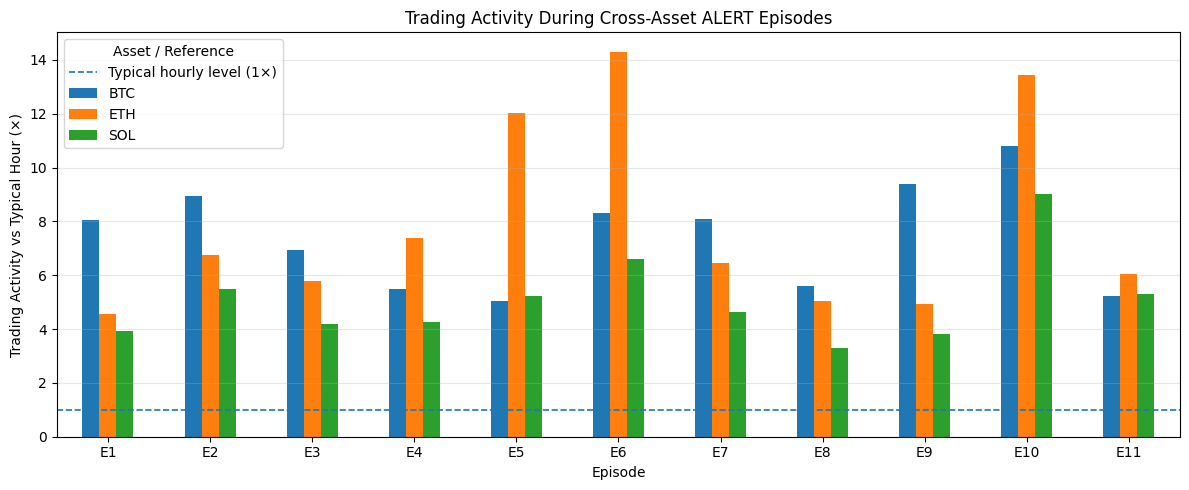

In [23]:
if episode_volume_summary.empty:
    print("No cross-asset ALERT episodes to plot for this dataset.")
else:
    # Prepare episode-level trading activity for visualization
    plot_volume = (
        episode_volume_summary
        .set_index("episode_id")
        [["BTC_ratio", "ETH_ratio", "SOL_ratio"]]
        .rename(columns={
            "BTC_ratio": "BTC",
            "ETH_ratio": "ETH",
            "SOL_ratio": "SOL"
        })
    )

    plot_volume.index = ["E" + str(i) for i in plot_volume.index]

    # Plot normalized trading activity
    ax = plot_volume.plot(kind="bar", figsize=(12, 5))

    ax.axhline(
        1,
        linestyle="--",
        linewidth=1.2,
        label="Typical hourly level (1×)"
    )

    ax.set_title("Trading Activity During Cross-Asset ALERT Episodes")
    ax.set_xlabel("Episode")
    ax.set_ylabel("Trading Activity vs Typical Hour (×)")
    ax.tick_params(axis="x", rotation=0)
    ax.grid(axis="y", alpha=0.3)
    ax.legend(title="Asset / Reference")

    plt.tight_layout()
    plt.show()

### Trading Activity During Alert Episodes

Trading activity was substantially elevated during all 11 cross-asset ALERT episodes relative to each asset's typical hourly level.

The comparison uses estimated USD trading activity (`VWAP × volume`) normalized by each asset's median hourly activity during the sample period. A value of 1× therefore represents the typical hourly level for that asset.

Across the detected episodes:

- BTC activity ranged from approximately **5× to 11×** its typical hourly level.
- ETH showed some of the largest increases, reaching approximately **14×** its typical level during Episode 6.
- SOL activity was also consistently elevated, reaching approximately **9×** its typical level during Episode 10.
- **Episode 10** showed particularly elevated activity across all three assets simultaneously, at approximately **10.79× for BTC, 13.45× for ETH and 9.01× for SOL**.

These results show that the cross-asset ALERT episodes coincided with substantially elevated trading activity. However, the analysis does not establish that increased trading activity caused the price movements or that the detected episodes represent specific external market events.

The USD activity estimates represent the selected Kraken USD trading pairs only and should not be interpreted as total global cryptocurrency trading volume.

## 8. Key Findings

The Crypto Market Health Monitor produced several key findings from the 721 hourly observations analysed for BTC/USD, ETH/USD and SOL/USD.

1. **Most market hours were classified as NORMAL.**  
   Approximately 77% of observations for each asset contained none of the unusual signal combinations required for an ALERT.

2. **ALERT observations were relatively selective.**  
   Only approximately 5–7% of hourly observations for each asset were classified as ALERT, allowing the framework to reduce a large stream of hourly data into a smaller set of observations for investigation.

3. **Cross-asset alerts were considerably less frequent.**  
   BTC, ETH and SOL were simultaneously classified as ALERT during only **18 of the 721 hours (2.5%)**.

4. **The 18 simultaneous alerts formed 11 distinct episodes.**  
   This indicates that synchronized unusual activity appeared in identifiable clusters rather than being evenly distributed throughout the sample.

5. **Alerts captured both upward and downward market movements.**  
   Some episodes occurred during broad positive price movements, while others occurred during declines or changing price direction. The framework therefore identifies unusual activity rather than predicting market direction.

6. **Cross-asset episodes coincided with elevated trading activity.**  
   Estimated USD trading activity during all 11 episodes was several times each asset's median hourly level, with particularly large increases observed during some ETH episodes and broad elevation across all three assets during Episode 10.

Together, these findings demonstrate how a transparent rule-based monitoring system can narrow continuous market data into a smaller set of periods that may warrant deeper analyst investigation.

## 9. Product & Operations Use Case

The monitoring framework demonstrates how continuous market data can be transformed into a smaller set of structured signals for investigation.

In a market-data environment, a similar workflow could support:

- **Market monitoring:** surface periods when unusual activity appears simultaneously across several assets.
- **Analyst prioritization:** reduce the number of hourly observations that require manual review by directing attention toward unusual cross-asset episodes.
- **Research workflows:** provide timestamps that analysts can investigate alongside market news, macroeconomic announcements or other external data.
- **Alert design:** combine multiple indicators rather than relying on a single price or volume threshold.
- **Product development:** provide a foundation for dashboards or monitoring tools where users can explore the indicators responsible for an alert.

For example, instead of reviewing all 721 hourly observations in this sample, the cross-asset layer reduced the investigation set to 18 simultaneous ALERT observations grouped into 11 episodes.

The prototype is intentionally simple and transparent. It is not intended to replace professional market-surveillance systems, predict cryptocurrency prices or generate trading recommendations. Its purpose is to demonstrate how market data can be structured into actionable monitoring signals for further research.

## 10. Limitations

This project is a prototype and has several limitations that should be considered when interpreting the results.

- **Limited time period:** The analysis covers approximately 30 days of hourly data. The observed thresholds and patterns may differ over longer market periods or under different market conditions.
- **Single exchange:** The dataset contains Kraken USD trading pairs only. Activity on other exchanges may differ, so the results should not be interpreted as representing the entire cryptocurrency market.
- **Relative thresholds:** The 90th percentile thresholds are calculated independently for each asset using this specific sample. They identify observations that are unusual relative to recent behaviour rather than universal definitions of abnormal market activity.
- **Rule-based classification:** The NORMAL, WATCH and ALERT categories are based on transparent analytical rules rather than a statistically validated market-risk or trading model.
- **Episode definition:** The three-hour grouping rule used to construct episodes is an analytical choice for this prototype and is not an industry-standard definition.
- **No causal inference:** The analysis identifies periods where unusual price movement, volatility and trading activity occurred together, but it does not establish what caused those movements.
- **No trading prediction:** The framework is designed for monitoring and investigation rather than forecasting prices or generating buy or sell signals.

Future development could test the framework over longer historical periods, incorporate additional assets or exchanges, evaluate alternative thresholds and integrate external market-event data for deeper investigation.

## 11. Conclusion

This project developed a rule-based Crypto Market Health Monitor using hourly Kraken data for BTC/USD, ETH/USD and SOL/USD.

By combining hourly price movement, trading volume and 24-hour rolling volatility, the framework classified market conditions into NORMAL, WATCH and ALERT states. A cross-asset monitoring layer then identified periods when unusual activity occurred simultaneously across all three assets.

From 721 hourly observations, only 18 hours (2.5%) triggered simultaneous ALERTs across BTC, ETH and SOL. These observations were grouped into 11 distinct episodes for further investigation. The episodes included both positive and negative price movements and consistently coincided with trading activity substantially above each asset's typical hourly level.

The project demonstrates how a relatively simple and transparent monitoring framework can reduce continuous market data into a focused set of investigation signals. Rather than attempting to predict market direction, the approach prioritizes interpretability and provides a structured starting point for analysts to investigate unusual cross-asset market behaviour.

Overall, the project combines data analysis, market monitoring and product-oriented thinking to demonstrate how raw cryptocurrency market data can be transformed into information that supports more focused research and operational decision-making.

## Appendix A: Kraken API Data Collection

This function was used during the initial data collection process. The main analysis uses saved CSV files to ensure reproducibility.

In [24]:
# Create a reusable function to collect and prepare hourly crypto data from Kraken

def get_crypto_data(pair):

    # 1. Request hourly market data from Kraken
    import requests
    url = "https://api.kraken.com/0/public/OHLC"

    params = {
        "pair": pair,
        "interval": 60
    }

    response = requests.get(url, params=params)
    data = response.json()

    # 2. Check that Kraken returned the data successfully
    if data["error"]:
        print("Kraken API error:", data["error"])
        return None

    # 3. Find the market-data key returned by Kraken
    result_key = [key for key in data["result"].keys() if key != "last"][0]

    raw_data = data["result"][result_key]

    # 4. Organize the raw data into a DataFrame
    columns = [
        "timestamp",
        "open",
        "high",
        "low",
        "close",
        "vwap",
        "volume",
        "trade_count"
    ]

    df = pd.DataFrame(raw_data, columns=columns)

    # 5. Convert timestamp into a readable date
    df["datetime"] = pd.to_datetime(df["timestamp"], unit="s")

    # 6. Convert market values from text to numbers
    numeric_columns = [
        "open", "high", "low", "close", "vwap", "volume"
    ]

    df[numeric_columns] = df[numeric_columns].apply(pd.to_numeric)

    # Remove the original computer timestamp
    df = df.drop(columns=["timestamp"])

    return df